# Atividade Prática 4: Manipulação e decisões de visualização de dados das IFES (1996–2026)

## Setup

In [ ]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
import seaborn as sns

print(f"pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {mpl.__version__} | seaborn {sns.__version__}")

TINTA, TINTA_2, MUDO = "#0b0b0b", "#52514e", "#898781"
GRADE, EIXO, SUPERFICIE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
AZUL, LARANJA, VERMELHO = "#2a78d6", "#eb6834", "#d03b3b"

sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EIXO, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "xtick.color": MUDO, "ytick.color": MUDO,
    "grid.color": GRADE, "grid.linewidth": 0.8, "axes.grid.axis": "y",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 10.5, "font.size": 10.5, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

SETA = dict(arrowstyle="-|>", color=MUDO, lw=1, shrinkA=2, shrinkB=4)


def br(x, casas=0):
    # Formata número no padrão brasileiro: 1.234,5 (e usa sinal de menos tipográfico).
    s = f"{x:,.{casas}f}".replace("-", "−")
    return s.replace(",", "§").replace(".", ",").replace("§", ".")


def fmt_eixo(casas=0, divisor=1, sufixo=""):
    return FuncFormatter(lambda v, _: br(v / divisor, casas) + sufixo)


PASTA_FIG = Path("figuras")
PASTA_FIG.mkdir(exist_ok=True)


def salvar(fig, nome):
    fig.savefig(PASTA_FIG / f"{nome}.png")

pandas 3.1.0 | numpy 2.5.4 | matplotlib 3.11.2 | seaborn 0.13.2


## Carregar, preparar e explorar os dados

In [5]:
CAMINHO = next(p for p in [Path("data/dados_investimento_e_vagas_ifes.csv"),
                           Path("dados_investimento_e_vagas_ifes.csv")] if p.exists())

bruto = pd.read_csv(CAMINHO, encoding="utf-8-sig")

RENOMEAR = {
    "investimento_total_ifes_bilhoes_brl": "inv_total",             # R$ bilhões
    "investimento_assistencia_estudantil_bilhoes_brl": "inv_assist",  # R$ bilhões
    "num_vagas_estudantes": "vagas_est",                            # nº de vagas (estoque)
    "num_vagas_docente": "vagas_doc",
    "num_vagas_tae": "vagas_tae",
    "num_terceirizados": "terceirizados",
}
df = bruto.rename(columns=RENOMEAR)
df.head()

,ano,inv_total,inv_assist,vagas_est,vagas_doc,vagas_tae,terceirizados
0,1996,32.1,0.02,342100,26800,43100,8200
1,1997,31.8,0.02,351400,27100,42800,8600
2,1998,30.5,0.03,362900,27400,42100,9100
3,1999,29.8,0.03,375200,27600,41500,9800
4,2000,31.2,0.04,391800,28100,41900,10400


In [6]:
print("formato:", df.shape)
print("colunas:", list(df.columns))
print("valores ausentes:", int(df.isna().sum().sum()))
print("anos únicos:", df["ano"].is_unique, "| anos consecutivos:", bool((df["ano"].diff().dropna() == 1).all()))
print("intervalo:", df["ano"].min(), "–", df["ano"].max())
df.dtypes.to_frame("tipo")

formato: (31, 7)
colunas: ['ano', 'inv_total', 'inv_assist', 'vagas_est', 'vagas_doc', 'vagas_tae', 'terceirizados']
valores ausentes: 0
anos únicos: True | anos consecutivos: True
intervalo: 1996 – 2026


,tipo
ano,int64
inv_total,float64
inv_assist,float64
vagas_est,int64
vagas_doc,int64
vagas_tae,int64
terceirizados,int64


### Escala das variáveis

In [7]:
num = df.drop(columns="ano")
escala = pd.DataFrame({
    "mínimo": num.min(),
    "máximo": num.max(),
    "ordem de grandeza do máximo (10^n)": np.floor(np.log10(num.max())).astype(int),
})
display(escala)

razao_vagas_inv = num["vagas_est"].max() / num["inv_total"].max()
razao_total_assist = num["inv_total"].max() / num["inv_assist"].max()
print(f"maior 'vagas_est' / maior 'inv_total'  = {razao_vagas_inv:,.0f}×".replace(",", "."))
print(f"maior 'inv_total' / maior 'inv_assist' = {razao_total_assist:.0f}×")

,mínimo,máximo,ordem de grandeza do máximo (10^n)
inv_total,29.80,76.50,1
inv_assist,0.02,1.32,0
vagas_est,342100.00,1385000.00,6
vagas_doc,26800.00,98100.00,4
vagas_tae,41500.00,77400.00,4
terceirizados,8200.00,59100.00,4


maior 'vagas_est' / maior 'inv_total'  = 18.105×
maior 'inv_total' / maior 'inv_assist' = 58×


### Colunas derivadas e recortes temporais

In [ ]:
df["alunos_por_docente"] = df["vagas_est"] / df["vagas_doc"]
df["alunos_por_tae"] = df["vagas_est"] / df["vagas_tae"]
df["assist_por_vaga_brl"] = df["inv_assist"] * 1e9 / df["vagas_est"]      # R$ por vaga de estudante

df["var_inv_pct"] = df["inv_total"].pct_change() * 100
df["var_assist_pct"] = df["inv_assist"].pct_change() * 100
df["var_vagas_pct"] = df["vagas_est"].pct_change() * 100
df["novas_vagas_est"] = df["vagas_est"].diff()

RECORTES = [  # (início, fim, rótulo, governo)
    (1996, 1998, "1996–98", "FHC I"),
    (1999, 2002, "1999–02", "FHC II"),
    (2003, 2006, "2003–06", "Lula I"),
    (2007, 2010, "2007–10", "Lula II"),
    (2011, 2014, "2011–14", "Dilma I"),
    (2015, 2018, "2015–18", "Dilma II/Temer"),
    (2019, 2022, "2019–22", "Bolsonaro"),
    (2023, 2026, "2023–26", "Lula III"),
]
ORDEM_PERIODOS = [r[2] for r in RECORTES]
GOVERNO = {r[2]: r[3] for r in RECORTES}
mapa_periodo = {a: rot for ini, fim, rot, _ in RECORTES for a in range(ini, fim + 1)}

df["periodo"] = pd.Categorical(df["ano"].map(mapa_periodo), categories=ORDEM_PERIODOS, ordered=True)
df["decada"] = (df["ano"] // 10 * 10).astype(str) + "s"

df[["ano", "periodo", "decada", "alunos_por_docente", "alunos_por_tae", "assist_por_vaga_brl",
    "var_inv_pct", "var_assist_pct", "var_vagas_pct"]].round(2).head(6)

,ano,periodo,decada,alunos_por_docente,alunos_por_tae,assist_por_vaga_brl,var_inv_pct,var_assist_pct,var_vagas_pct
0,1996,1996–98,1990s,12.76,7.94,58.46,NaN,NaN,NaN
1,1997,1996–98,1990s,12.97,8.21,56.92,-0.93,0.00,2.72
2,1998,1996–98,1990s,13.24,8.62,82.67,-4.09,50.00,3.27
3,1999,1999–02,1990s,13.59,9.04,79.96,-2.30,0.00,3.39
4,2000,1999–02,2000s,13.94,9.35,102.09,4.70,33.33,4.42
5,2001,1999–02,2000s,14.20,9.70,97.44,0.96,0.00,4.77


## Evolução temporal e ajuste de escalas (`groupby`)

Primeiro, o **crescimento absoluto** por década e por mandato. Em cada mandato calculo a diferença entre o valor do **último ano** e o do último ano do mandato anterior (no primeiro, a base é 1996).

In [9]:
por_decada = (df.groupby("decada")
                .agg(anos=("ano", "count"),
                     inv_total_media=("inv_total", "mean"),
                     inv_total_ultimo_ano=("inv_total", "last"),
                     vagas_est_ultimo_ano=("vagas_est", "last"),
                     novas_vagas_na_decada=("novas_vagas_est", "sum"))
                .round(1))
display(por_decada)

fim_periodo = df.groupby("periodo", observed=True)[["inv_total", "vagas_est"]].last()
base_1996 = df.loc[df["ano"] == 1996, ["inv_total", "vagas_est"]].iloc[0]

cresc_abs = fim_periodo.diff()
cresc_abs.iloc[0] = (fim_periodo.iloc[0] - base_1996).to_numpy()
cresc_abs.columns = ["Δ invest. total (R$ bi)", "Δ vagas de estudantes"]
cresc_abs.insert(0, "governo", [GOVERNO[p] for p in cresc_abs.index])
cresc_abs.round(1)

,anos,inv_total_media,inv_total_ultimo_ano,vagas_est_ultimo_ano,novas_vagas_na_decada
decada,,,,,
1990s,4,31.0,29.8,375200,33100.0
2000s,10,43.6,66.8,814900,439700.0
2010s,10,69.2,58.2,1312000,497100.0
2020s,7,56.0,61.8,1385000,73000.0


,governo,Δ invest. total (R$ bi),Δ vagas de estudantes
periodo,,,
1996–98,FHC I,-1.6,20800.0
1999–02,FHC II,1.9,66200.0
2003–06,Lula I,15.9,147100.0
2007–10,Lula II,21.2,325900.0
2011–14,Dilma I,7.0,249900.0
2015–18,Dilma II/Temer,-13.7,146000.0
2019–22,Bolsonaro,-13.5,31000.0
2023–26,Lula III,12.5,56000.0


`decada` agrupa períodos de tamanhos desiguais (a década de 1990 só tem 1996–99 e a de 2020 tem 2020–26), por isso as comparações de crescimento usam os mandatos (4 anos cada, exceto o primeiro).

### Decisão de visualização: Evolução do Investimento Total e das Vagas de Estudantes

Opções consideradas: (a) eixo único; (b) eixo duplo; (c) índice base 1996 = 100; (d) dois painéis empilhados com eixo x compartilhado e eixo y independente. A opção (d) foi a escolhida; as opções (a) e (b) são mostradas na Figura 2 para evidenciar por que foram descartadas.

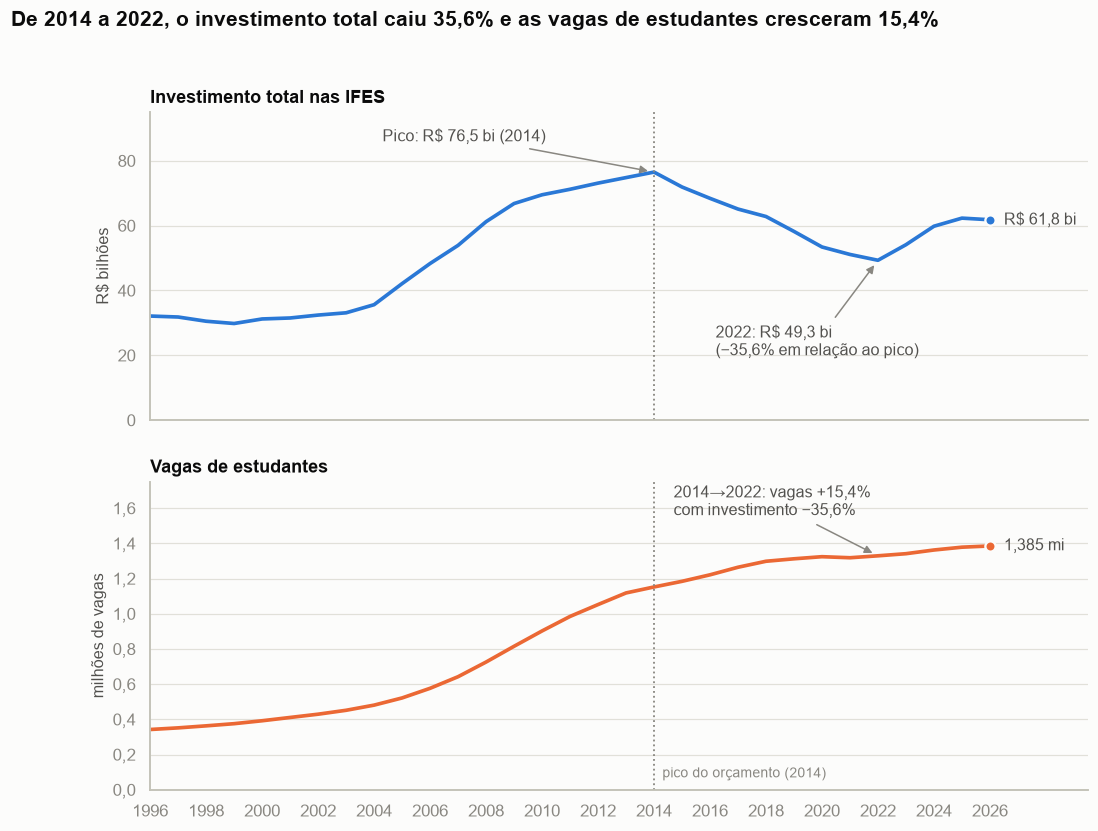

In [ ]:
pico = df.loc[df["inv_total"].idxmax()]
v22 = df.loc[df["ano"] == 2022].iloc[0]
v26 = df.iloc[-1]
queda_pico_22 = (v22["inv_total"] / pico["inv_total"] - 1) * 100
cresc_vagas_14_22 = (v22["vagas_est"] / df.loc[df["ano"] == 2014, "vagas_est"].iloc[0] - 1) * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True, gridspec_kw={"hspace": 0.2})

sns.lineplot(data=df, x="ano", y="inv_total", ax=ax1, color=AZUL, linewidth=2.4)
ax1.set_ylim(0, 95)
ax1.set_ylabel("R$ bilhões")
ax1.yaxis.set_major_formatter(fmt_eixo(0))
ax1.set_title("Investimento total nas IFES")
ax1.annotate(f"Pico: R$ {br(pico['inv_total'], 1)} bi ({int(pico['ano'])})",
             xy=(pico["ano"], pico["inv_total"]), xytext=(2004.3, 86), arrowprops=SETA, color=TINTA_2)
ax1.annotate(f"2022: R$ {br(v22['inv_total'], 1)} bi\n({br(queda_pico_22, 1)}% em relação ao pico)",
             xy=(2022, v22["inv_total"]), xytext=(2016.2, 20), arrowprops=SETA, color=TINTA_2)
ax1.scatter(v26["ano"], v26["inv_total"], s=45, color=AZUL, edgecolor=SUPERFICIE, linewidth=1.5, zorder=5)
ax1.text(v26["ano"] + 0.5, v26["inv_total"], f"R$ {br(v26['inv_total'], 1)} bi", va="center", color=TINTA_2)

sns.lineplot(data=df, x="ano", y="vagas_est", ax=ax2, color=LARANJA, linewidth=2.4)
ax2.set_ylim(0, 1_750_000)
ax2.set_ylabel("milhões de vagas")
ax2.yaxis.set_major_formatter(fmt_eixo(1, divisor=1e6))
ax2.set_title("Vagas de estudantes")
ax2.scatter(v26["ano"], v26["vagas_est"], s=45, color=LARANJA, edgecolor=SUPERFICIE, linewidth=1.5, zorder=5)
ax2.text(v26["ano"] + 0.5, v26["vagas_est"], f"{br(v26['vagas_est'] / 1e6, 3)} mi", va="center", color=TINTA_2)
ax2.annotate(f"2014→2022: vagas +{br(cresc_vagas_14_22, 1)}%\ncom investimento {br(queda_pico_22, 1)}%",
             xy=(2022, v22["vagas_est"]), xytext=(2014.7, 1_560_000), arrowprops=SETA, color=TINTA_2)

for ax in (ax1, ax2):
    ax.axvline(2014, color=MUDO, linestyle=":", linewidth=1.2)
ax2.text(2014.3, 70_000, "pico do orçamento (2014)", color=MUDO, fontsize=9)

ax2.set_xlim(1996, 2029.5)
ax2.set_xticks(range(1996, 2027, 2))
ax2.set_xlabel("")

fig.suptitle(f"De 2014 a 2022, o investimento total caiu {br(abs(queda_pico_22), 1)}% "
             f"e as vagas de estudantes cresceram {br(cresc_vagas_14_22, 1)}%",
             x=0.01, ha="left", y=0.995, fontsize=13.5, fontweight="bold")
salvar(fig, "01_evolucao_investimento_vagas")
plt.show()

### Relatório visual: Figura 1

números: invest. total 32,1 (1996) -> 76,5 (2014, pico) -> 49,3 (2022) -> 61,8 (2026)
queda de 35,6% de 2014 a 2022; vagas +15,4% no mesmo período

vagas: 342 mil (1996) -> 1,385 milhão (2026)
em 2026 o invest. ainda está 19,2% abaixo de 2014

design: por que 2 painéis, eixo x compartilhado, eixo y começando em 0, anotação no lugar de legenda, azul e laranja

### Alternativas descartadas:

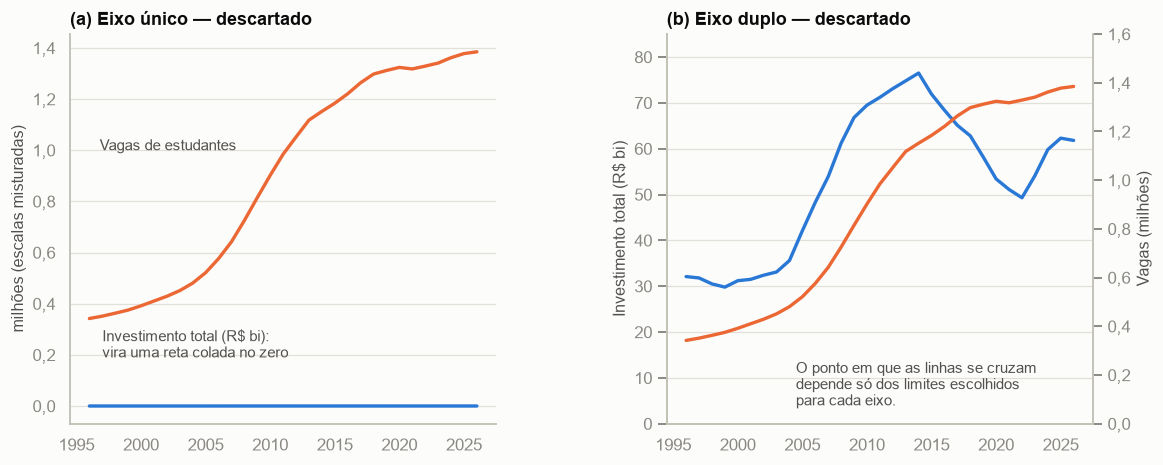

In [11]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"wspace": 0.4})

# (a) eixo único com valores brutos
axa.plot(df["ano"], df["inv_total"], color=AZUL, linewidth=2.2)
axa.plot(df["ano"], df["vagas_est"], color=LARANJA, linewidth=2.2)
axa.set_title("(a) Eixo único — descartado")
axa.yaxis.set_major_formatter(fmt_eixo(1, divisor=1e6))
axa.set_ylabel("milhões (escalas misturadas)")
axa.text(1997, 190_000, "Investimento total (R$ bi):\nvira uma reta colada no zero", color=TINTA_2, fontsize=9.5)
axa.text(1996.8, 1_000_000, "Vagas de estudantes", color=TINTA_2, fontsize=9.5)

# (b) eixo duplo
axb.plot(df["ano"], df["inv_total"], color=AZUL, linewidth=2.2)
axb.set_ylim(0, 85)
axb.set_ylabel("Investimento total (R$ bi)")
axb.set_title("(b) Eixo duplo — descartado")
axb2 = axb.twinx()
axb2.plot(df["ano"], df["vagas_est"], color=LARANJA, linewidth=2.2)
axb2.set_ylim(0, 1_600_000)
axb2.yaxis.set_major_formatter(fmt_eixo(1, divisor=1e6))
axb2.set_ylabel("Vagas (milhões)")
axb2.grid(False)
axb2.spines["right"].set_visible(True)
axb2.spines["right"].set_color(EIXO)
axb.text(2004.5, 4, "O ponto em que as linhas se cruzam\ndepende só dos limites escolhidos\npara cada eixo.", color=TINTA_2, fontsize=9.5)

salvar(fig, "02_alternativas_descartadas_escala")
plt.show()

### Relatório visual: Figura 2 (alternativas descartadas)

- No painel (a), o investimento total (máx. R$ 76,5 bi) fica colado ao zero, ao lado de vagas na casa do milhão: a série parece constante, embora tenha caído 35,6% entre 2014 e 2022.
- No painel (b), as duas séries ficam legíveis, mas a posição relativa das curvas e o cruzamento aparente entre elas não vêm dos dados, e sim dos limites de eixo escolhidos (0–85 e 0–1,6 mi).

**O design**

- **(a) Eixo único** destrói a informação da série de menor magnitude 
- **(b) Eixo duplo** é visualmente tentador, mas permite fabricar correlações e "cruzamentos" ao gosto do autor; o leitor não consegue saber se a proximidade das linhas é fato ou escolha de escala. Por isso é evitado.
- **(c) Índice base 1996 = 100** (não plotado) resolveria a escala, mas esconderia os valores absolutos, que a atividade pede para analisar; fica como complemento possível.
- A solução adotada (Figura 1) mantém a unidade e a escala natural de cada série e entrega o alinhamento temporal pelo eixo x compartilhado.

## Proporção da força de trabalho: docentes × TAEs

In [12]:
d = df.set_index("ano")
anos_ref = [1996, 2004, 2010, 2014, 2022, 2026]
display(d.loc[anos_ref, ["alunos_por_docente", "alunos_por_tae"]].round(2))

media_periodo = (df.groupby("periodo", observed=True)[["alunos_por_docente", "alunos_por_tae"]]
                   .mean().round(2))
media_periodo.insert(0, "governo", [GOVERNO[p] for p in media_periodo.index])
display(media_periodo)

cresc_96_26 = ((d.loc[2026, ["vagas_est", "vagas_doc", "vagas_tae"]] /
                d.loc[1996, ["vagas_est", "vagas_doc", "vagas_tae"]] - 1) * 100).round(1)
cresc_14_26 = ((d.loc[2026, ["vagas_est", "vagas_doc", "vagas_tae"]] /
                d.loc[2014, ["vagas_est", "vagas_doc", "vagas_tae"]] - 1) * 100).round(1)
print("crescimento 1996→2026 (%):\n", cresc_96_26.to_string(), "\n")
print("crescimento 2014→2026 (%):\n", cresc_14_26.to_string())

cruz = int(df.loc[df["alunos_por_tae"] > df["alunos_por_docente"], "ano"].min())
print("\nprimeiro ano em que alunos/TAE > alunos/docente:", cruz)

,alunos_por_docente,alunos_por_tae
ano,,
1996,12.76,7.94
2004,15.40,10.87
2010,13.42,13.50
2014,13.46,15.00
2022,14.12,19.04
2026,14.12,19.16


,governo,alunos_por_docente,alunos_por_tae
periodo,,,
1996–98,FHC I,12.99,8.26
1999–02,FHC II,14.08,9.53
2003–06,Lula I,15.08,11.00
2007–10,Lula II,13.95,12.83
2011–14,Dilma I,13.49,14.56
2015–18,Dilma II/Temer,13.78,16.17
2019–22,Bolsonaro,14.11,18.33
2023–26,Lula III,14.10,19.10


crescimento 1996→2026 (%):
 vagas_est    304.9
vagas_doc    266.0
vagas_tae     67.7 

crescimento 2014→2026 (%):
 vagas_est    20.2
vagas_doc    14.6
vagas_tae    -5.9

primeiro ano em que alunos/TAE > alunos/docente: 2010


### Decisão de visualização: evolução concomitante das duas razões

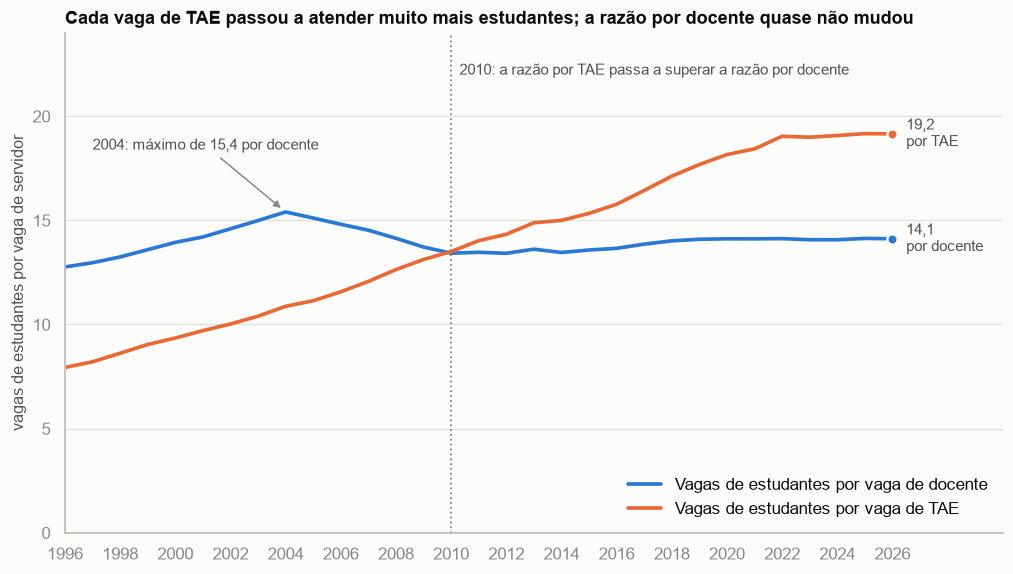

In [13]:
a_fim = int(df["ano"].iloc[-1])
r_doc_fim = df["alunos_por_docente"].iloc[-1]
r_tae_fim = df["alunos_por_tae"].iloc[-1]
i_max_doc = df["alunos_por_docente"].idxmax()

fig, ax = plt.subplots(figsize=(11, 5.9))
sns.lineplot(data=df, x="ano", y="alunos_por_docente", ax=ax, color=AZUL, linewidth=2.4,
             label="Vagas de estudantes por vaga de docente")
sns.lineplot(data=df, x="ano", y="alunos_por_tae", ax=ax, color=LARANJA, linewidth=2.4,
             label="Vagas de estudantes por vaga de TAE")

for valor, cor, nome in [(r_doc_fim, AZUL, "docente"), (r_tae_fim, LARANJA, "TAE")]:
    ax.scatter(a_fim, valor, s=45, color=cor, edgecolor=SUPERFICIE, linewidth=1.5, zorder=5)
    ax.text(a_fim + 0.5, valor, f"{br(valor, 1)}\npor {nome}", va="center", color=TINTA_2, fontsize=10)

ax.axvline(cruz, color=MUDO, linestyle=":", linewidth=1.2)
ax.text(cruz + 0.3, 22.0, f"{cruz}: a razão por TAE passa a superar a razão por docente",
        color=TINTA_2, fontsize=9.5)
ax.annotate(f"{int(df.loc[i_max_doc, 'ano'])}: máximo de {br(df.loc[i_max_doc, 'alunos_por_docente'], 1)} por docente",
            xy=(df.loc[i_max_doc, "ano"], df.loc[i_max_doc, "alunos_por_docente"]),
            xytext=(1997, 18.4), arrowprops=SETA, color=TINTA_2, fontsize=9.5)

ax.set_ylim(0, 24)
ax.set_yticks(range(0, 25, 5))
ax.yaxis.set_major_formatter(fmt_eixo(0))
ax.set_ylabel("vagas de estudantes por vaga de servidor")
ax.set_xlim(1996, 2030)
ax.set_xticks(range(1996, 2027, 2))
ax.set_xlabel("")
ax.legend(loc="lower right", ncol=1)
ax.set_title("Cada vaga de TAE passou a atender muito mais estudantes; a razão por docente quase não mudou")
salvar(fig, "03_proporcao_alunos_por_servidor")
plt.show()

### Relatório visual: Figura 3

números: alunos por docente 12,8 (1996), máximo 15,4 (2004), 14,1 (2026)

alunos por TAE 7,9 (1996) -> 19,2 (2026)

as duas se cruzam em 2010 (13,5 por TAE e 13,4 por docente)

1996->2026: vagas de estudantes +304,9%, docentes +266,0%, TAE +67,7%; 2014->2026: TAE -5,9%

design: mesmo eixo y (mesma unidade), linhas, eixo começando em 0, rótulo direto + legenda


## Correlação entre fatores e desempenho orçamentário (método `agg`)

In [14]:
agg_basico = (df.groupby("periodo", observed=True)[["inv_assist", "vagas_est"]]
                .agg(["mean", "median", "sum"]))
agg_basico.columns = [f"{v} — {s}" for v, s in agg_basico.columns]
agg_basico = agg_basico.rename(columns=lambda c: c.replace("inv_assist", "assistência (R$ bi)")
                                                   .replace("vagas_est", "vagas de estudantes")
                                                   .replace("mean", "média").replace("median", "mediana")
                                                   .replace("sum", "soma"))

extra = df.groupby("periodo", observed=True).agg(novas_vagas=("novas_vagas_est", "sum"))
agg_basico["novas vagas no período"] = extra["novas_vagas"]
agg_basico["assistência por vaga (R$)"] = (
    df.groupby("periodo", observed=True)["inv_assist"].sum() * 1e9 /
    df.groupby("periodo", observed=True)["vagas_est"].sum()
)
agg_basico.insert(0, "governo", [GOVERNO[p] for p in agg_basico.index])
agg_basico.round(2)

,governo,assistência (R$ bi) — média,assistência (R$ bi) — mediana,assistência (R$ bi) — soma,vagas de estudantes — média,vagas de estudantes — mediana,vagas de estudantes — soma,novas vagas no período,assistência por vaga (R$)
periodo,,,,,,,,,
1996–98,FHC I,0.02,0.02,0.07,352133.33,351400.0,1056400,20800.0,66.26
1999–02,FHC II,0.04,0.04,0.16,401650.00,401150.0,1606600,66200.0,99.59
2003–06,Lula I,0.11,0.10,0.44,507375.00,501000.0,2029500,147100.0,216.80
2007–10,Lula II,0.52,0.52,2.06,771125.00,770150.0,3084500,325900.0,667.86
2011–14,Dilma I,1.14,1.16,4.57,1076625.00,1085000.0,4306500,249900.0,1061.19
2015–18,Dilma II/Temer,1.26,1.27,5.04,1241750.00,1242500.0,4967000,146000.0,1014.70
2019–22,Bolsonaro,1.10,1.12,4.40,1320750.00,1321000.0,5283000,31000.0,832.86
2023–26,Lula III,1.19,1.21,4.76,1366500.00,1370000.0,5466000,56000.0,870.84


### Decisão de visualização

In [15]:
d = df.set_index("ano")

def r(a, b, recorte=slice(None)):
    return d.loc[recorte, a].corr(d.loc[recorte, b])

tabela_corr = pd.DataFrame({
    "assistência × vagas": [r("inv_assist", "vagas_est"),
                            r("inv_assist", "vagas_est", slice(1996, 2014)),
                            r("inv_assist", "vagas_est", slice(2014, 2026)),
                            d.loc[2015:, "var_assist_pct"].corr(d.loc[2015:, "var_vagas_pct"])],
}, index=["níveis, 1996–2026", "níveis, 1996–2014", "níveis, 2014–2026",
          "variações anuais, 2015–2026"]).round(2)
display(tabela_corr)

niveis = d[["inv_total", "inv_assist", "vagas_est"]].corr()
variacoes = d.loc[2015:, ["var_inv_pct", "var_assist_pct", "var_vagas_pct"]].corr()
print("Níveis (1996–2026):\n", niveis.round(2).to_string(), "\n")
print("Variações anuais (2015–2026):\n", variacoes.round(2).to_string())

,assistência × vagas
"níveis, 1996–2026",0.97
"níveis, 1996–2014",0.99
"níveis, 2014–2026",-0.53
"variações anuais, 2015–2026",0.05


Níveis (1996–2026):
             inv_total  inv_assist  vagas_est
inv_total        1.00        0.85       0.76
inv_assist       0.85        1.00       0.97
vagas_est        0.76        0.97       1.00 

Variações anuais (2015–2026):
                 var_inv_pct  var_assist_pct  var_vagas_pct
var_inv_pct            1.00            0.85          -0.19
var_assist_pct         0.85            1.00           0.05
var_vagas_pct         -0.19            0.05           1.00


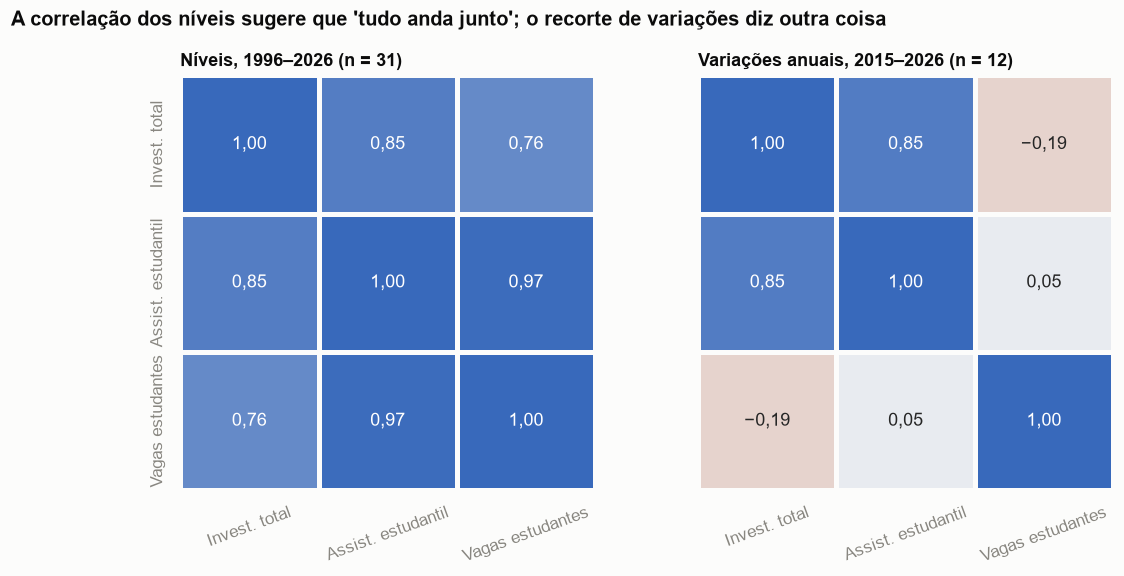

In [16]:
CMAP_DIV = sns.diverging_palette(22, 255, s=80, l=45, as_cmap=True, center="light")  # negativo=laranja, positivo=azul
rotulos = ["Invest. total", "Assist. estudantil", "Vagas estudantes"]

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.9), gridspec_kw={"wspace": 0.12})
for ax, m, titulo in [(axs[0], niveis, "Níveis, 1996–2026 (n = 31)"),
                      (axs[1], variacoes, "Variações anuais, 2015–2026 (n = 12)")]:
    m2 = m.set_axis(rotulos, axis=0).set_axis(rotulos, axis=1)
    sns.heatmap(m2, annot=m2.map(lambda v: br(v, 2)).to_numpy(), fmt="", vmin=-1, vmax=1,
                cmap=CMAP_DIV, cbar=False, square=True, linewidths=3, linecolor=SUPERFICIE,
                annot_kws={"size": 11.5}, ax=ax)
    ax.set_title(titulo)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(False)
axs[1].set_yticklabels([])
fig.suptitle("A correlação dos níveis sugere que 'tudo anda junto'; o recorte de variações diz outra coisa",
             x=0.01, ha="left", y=1.0, fontsize=13, fontweight="bold")
salvar(fig, "04_heatmap_correlacao_descartado")
plt.show()

### Relatório visual: Figura 4

números (níveis, 1996-2026): assistência x vagas 0,97; 
assistência x invest. total 0,85;  
total x vagas 0,76
assistência x vagas: 0,99 até 2014 e -0,53 depois

variações anuais 2015-2026 (só 12 pontos): assistência x vagas 0,05; invest. total x vagas -0,19

design: heatmap com paleta divergente de -1 a +1; correlação de nível mistura tendência com relação de verdade, por isso o bubble (Fig. 5) 

R$ por vaga: 1996 = 58 | 2014 = 1146 | 2022 = 737 | 2026 = 881
2026 sob a proporção de 2014: R$ 1.587 bi | observado: R$ 1.22 bi | lacuna: R$ 0.367 bi (-23.1%)


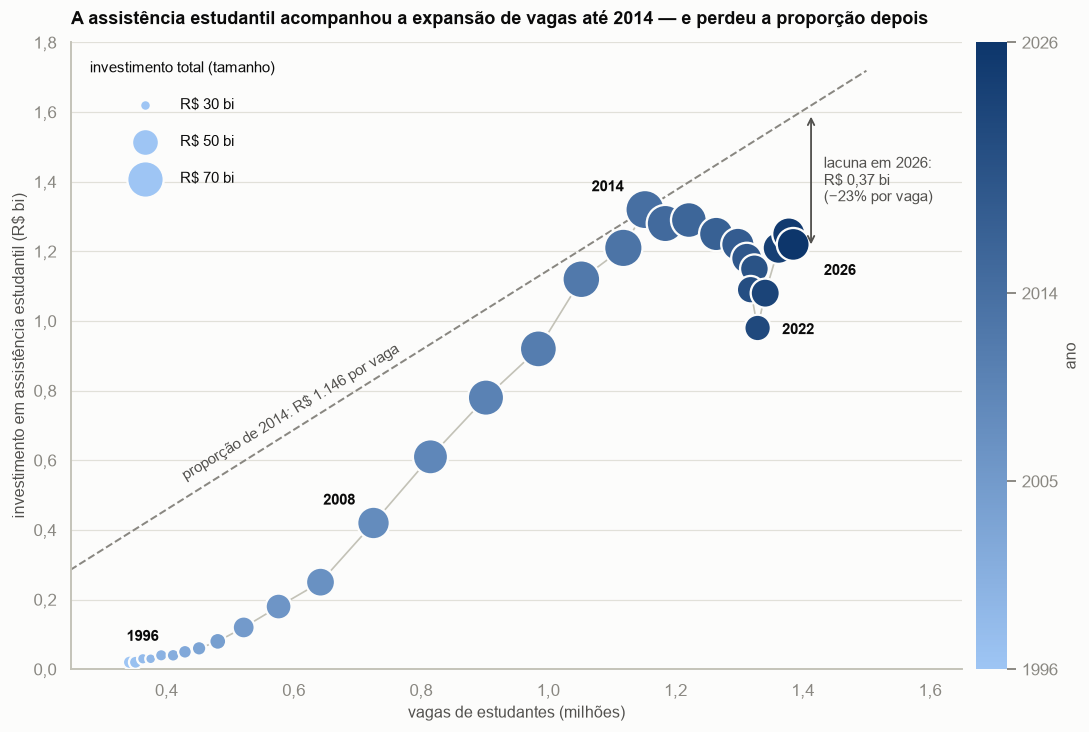

In [17]:
r14 = df.loc[df["ano"] == 2014].iloc[0]
rv_pico = r14["assist_por_vaga_brl"]                 # R$ por vaga no ano de maior proporcionalidade
v96 = df.iloc[0]; v22 = df.loc[df["ano"] == 2022].iloc[0]; v26 = df.iloc[-1]
ref_2026 = rv_pico * v26["vagas_est"] / 1e9          # assistência que 2026 teria sob a proporção de 2014
lacuna = ref_2026 - v26["inv_assist"]
print(f"R$ por vaga: 1996 = {v96['assist_por_vaga_brl']:.0f} | 2014 = {rv_pico:.0f} | "
      f"2022 = {v22['assist_por_vaga_brl']:.0f} | 2026 = {v26['assist_por_vaga_brl']:.0f}")
print(f"2026 sob a proporção de 2014: R$ {ref_2026:.3f} bi | observado: R$ {v26['inv_assist']:.2f} bi | "
      f"lacuna: R$ {lacuna:.3f} bi ({(v26['assist_por_vaga_brl']/rv_pico-1)*100:.1f}%)")

CMAP_SEQ = sns.blend_palette(["#9ec5f4", "#0d366b"], as_cmap=True)     # um matiz (azul), claro → escuro
norm_ano = Normalize(df["ano"].min(), df["ano"].max())
LIM_INV, S_MIN, S_MAX = (30, 80), 50, 700                             # tamanho ∝ investimento total

fig, ax = plt.subplots(figsize=(11, 7.4))

# trajetória temporal (conecta os anos em ordem) e linha de proporcionalidade
ax.plot(df["vagas_est"], df["inv_assist"], color=EIXO, linewidth=1.1, zorder=1)
xs = np.array([0, 1.5e6])
ax.plot(xs, rv_pico * xs / 1e9, color=MUDO, linestyle="--", linewidth=1.3, zorder=1)
ax.text(0.43e6, rv_pico * 0.43e6 / 1e9 + 0.05, f"proporção de 2014: R$ {br(rv_pico)} por vaga",
        color=TINTA_2, fontsize=9.5, rotation=31, rotation_mode="anchor")

sns.scatterplot(data=df, x="vagas_est", y="inv_assist", size="inv_total", sizes=(S_MIN, S_MAX),
                size_norm=LIM_INV, hue="ano", hue_norm=norm_ano, palette=CMAP_SEQ,
                edgecolor=SUPERFICIE, linewidth=1.5, legend=False, ax=ax, zorder=3)

# rótulos de anos-chave
for ano_, dx, dy, ha in [(1996, -2, 14, "left"), (2008, -12, 12, "right"), (2014, -14, 12, "right"),
                         (2022, 16, -4, "left"), (2026, 20, -20, "left")]:
    linha = df.loc[df["ano"] == ano_].iloc[0]
    ax.annotate(str(ano_), (linha["vagas_est"], linha["inv_assist"]), xytext=(dx, dy),
                textcoords="offset points", ha=ha, color=TINTA, fontsize=10, fontweight="bold")

# lacuna em 2026
ax.annotate("", xy=(v26["vagas_est"] + 28_000, ref_2026), xytext=(v26["vagas_est"] + 28_000, v26["inv_assist"]),
            arrowprops=dict(arrowstyle="<->", color=TINTA_2, lw=1.2, shrinkA=0, shrinkB=0))
ax.text(v26["vagas_est"] + 48_000, (ref_2026 + v26["inv_assist"]) / 2,
        f"lacuna em 2026:\nR$ {br(lacuna, 2)} bi\n({br((v26['assist_por_vaga_brl']/rv_pico-1)*100, 0)}% por vaga)",
        color=TINTA_2, fontsize=9.5, va="center")

ax.set_xlim(250_000, 1_650_000)
ax.set_ylim(0, 1.8)
ax.set_xlabel("vagas de estudantes (milhões)")
ax.set_ylabel("investimento em assistência estudantil (R$ bi)")
ax.xaxis.set_major_formatter(fmt_eixo(1, divisor=1e6))
ax.yaxis.set_major_formatter(fmt_eixo(1))
ax.grid(axis="x", visible=False)
ax.set_title("A assistência estudantil acompanhou a expansão de vagas até 2014 — e perdeu a proporção depois",
             pad=12)

# colorbar (ano) + legenda de tamanho (investimento total)
cb = fig.colorbar(ScalarMappable(norm=norm_ano, cmap=CMAP_SEQ), ax=ax, pad=0.015, fraction=0.035)
cb.set_ticks([1996, 2005, 2014, 2026])
cb.set_label("ano")
cb.outline.set_visible(False)

def area(v):
    return S_MIN + (v - LIM_INV[0]) / (LIM_INV[1] - LIM_INV[0]) * (S_MAX - S_MIN)

handles = [ax.scatter([], [], s=area(v), color="#9ec5f4", edgecolor=SUPERFICIE, linewidth=1.5) for v in (30, 50, 70)]
ax.legend(handles, ["R$ 30 bi", "R$ 50 bi", "R$ 70 bi"], title="investimento total (tamanho)",
          loc="upper left", labelspacing=1.5, borderpad=0.8, title_fontsize=9.5, fontsize=9.5,
          handletextpad=1.4)
salvar(fig, "05_bubble_assistencia_vs_vagas")
plt.show()

### Figura 5 (bubble chart foi escolhido):

números: assistência por vaga R$ 58 (1996) -> R$ 1.146 (2014) -> R$ 737 (2022) -> R$ 881 (2026), 23,1% abaixo de 2014

com a proporção de 2014, 2026 teria R$ 1,59 bi (tem 1,22): lacuna de R$ 0,37 bi

atenção: a linha de proporção está ancorada em 2014, então 2014 estar em cima dela é por construção

design: bolha (tamanho = invest. total, cor = ano), linha ligando os anos, eixo y a partir de 0, só alguns anos rotulados

## Filtragem condicional de anos críticos (`filter`)

In [18]:
TOL_ESTAGNACAO = 1.0     # variação percentual máxima para contar como estagnação
BASE_MINIMA = 0.10       # R$ bi: abaixo disso, a resolução de 0,01 do dado domina a variação

df["cond_assist"] = df["var_assist_pct"] <= TOL_ESTAGNACAO
df["cond_vagas"] = df["var_vagas_pct"] > 0
df["regra_atendida"] = df["cond_assist"] & df["cond_vagas"]
df["inconclusivo"] = df["regra_atendida"] & (df["inv_assist"].shift(1) < BASE_MINIMA)
df["ano_critico"] = df["regra_atendida"] & ~df["inconclusivo"]

colunas = ["ano", "inv_assist", "var_assist_pct", "var_vagas_pct", "novas_vagas_est"]
criticos = df.loc[df["ano_critico"], colunas]
inconclusivos = df.loc[df["inconclusivo"], colunas]
print("Anos críticos:", criticos["ano"].tolist())
print("Anos inconclusivos (ruído de arredondamento):", inconclusivos["ano"].tolist())
display(criticos.round(2).set_index("ano"))

Anos críticos: [2015, 2016, 2017, 2018, 2019, 2020, 2022, 2026]
Anos inconclusivos (ruído de arredondamento): [1997, 1999, 2001]


,inv_assist,var_assist_pct,var_vagas_pct,novas_vagas_est
ano,,,,
2015,1.28,-3.03,2.78,32000.0
2016,1.29,0.78,3.12,37000.0
2017,1.25,-3.10,3.52,43000.0
2018,1.22,-2.40,2.69,34000.0
2019,1.18,-3.28,1.08,14000.0
2020,1.15,-2.54,0.91,12000.0
2022,0.98,-10.09,0.83,11000.0
2026,1.22,-2.40,0.51,7000.0


In [19]:
# Uso explícito do groupby(...).filter: mantém só os mandatos com 2 ou mais anos críticos
periodos_recorrentes = (df.groupby("periodo", observed=True)
                          .filter(lambda g: g["ano_critico"].sum() >= 2))
print("Mandatos com ≥ 2 anos críticos:", periodos_recorrentes["periodo"].astype(str).unique().tolist())
print("Anos críticos por mandato:")
display(df.groupby("periodo", observed=True)["ano_critico"].sum().to_frame("anos críticos").T)

# o caso-limite 2021: houve corte, mas as vagas recuaram → não entra no filtro
display(df.loc[df["ano"] == 2021, colunas].round(2).set_index("ano"))

queda_14_22 = (d.loc[2022, "inv_assist"] / d.loc[2014, "inv_assist"] - 1) * 100
print(f"assistência 2014→2022: {queda_14_22:.1f}%  | vagas 2014→2022: +{d.loc[2022,'vagas_est'] - d.loc[2014,'vagas_est']:,.0f}")
print(f"assistência 2026 vs pico (2014): {(d.loc[2026,'inv_assist']/d.loc[2014,'inv_assist']-1)*100:.1f}%")

Mandatos com ≥ 2 anos críticos: ['2015–18', '2019–22']
Anos críticos por mandato:


periodo,1996–98,1999–02,2003–06,2007–10,2011–14,2015–18,2019–22,2023–26
anos críticos,0,0,0,0,0,4,3,1


,inv_assist,var_assist_pct,var_vagas_pct,novas_vagas_est
ano,,,,
2021,1.09,-5.22,-0.45,-6000.0


assistência 2014→2022: -25.8%  | vagas 2014→2022: +177,000
assistência 2026 vs pico (2014): -7.6%


### Decisão de visualização

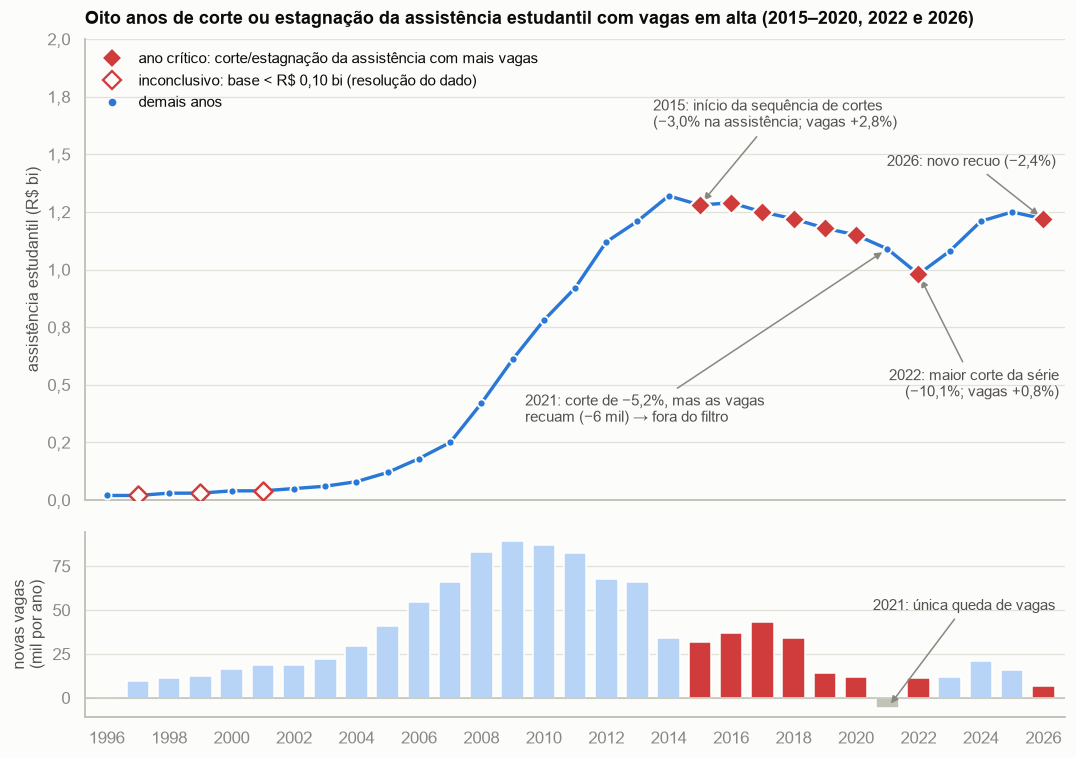

In [20]:
crit = df["ano_critico"]
inc = df["inconclusivo"]
normal = ~(crit | inc)

fig, (ax, axb) = plt.subplots(2, 1, figsize=(11.5, 8), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.2], "hspace": 0.1})

# --- painel superior: assistência estudantil ---
ax.plot(df["ano"], df["inv_assist"], color=AZUL, linewidth=2.2, zorder=2)
ax.scatter(df.loc[normal, "ano"], df.loc[normal, "inv_assist"], s=28, color=AZUL,
           edgecolor=SUPERFICIE, linewidth=1.2, zorder=3)
ax.scatter(df.loc[inc, "ano"], df.loc[inc, "inv_assist"], s=70, marker="D", facecolor=SUPERFICIE,
           edgecolor=VERMELHO, linewidth=1.6, zorder=4)
ax.scatter(df.loc[crit, "ano"], df.loc[crit, "inv_assist"], s=95, marker="D", color=VERMELHO,
           edgecolor=SUPERFICIE, linewidth=1.5, zorder=5)

ax.annotate("2015: início da sequência de cortes\n(−3,0% na assistência; vagas +2,8%)",
            xy=(2015, 1.28), xytext=(2013.5, 1.62), arrowprops=SETA, color=TINTA_2, fontsize=9.5)
ax.annotate("2021: corte de −5,2%, mas as vagas\nrecuam (−6 mil) → fora do filtro",
            xy=(2021, 1.09), xytext=(2009.4, 0.34), arrowprops=SETA, color=TINTA_2, fontsize=9.5)
ax.annotate("2022: maior corte da série\n(−10,1%; vagas +0,8%)",
            xy=(2022, 0.98), xytext=(2026.5, 0.45), arrowprops=SETA, color=TINTA_2, fontsize=9.5, ha="right")
ax.annotate("2026: novo recuo (−2,4%)", xy=(2026, 1.22), xytext=(2026.4, 1.45), arrowprops=SETA,
            color=TINTA_2, fontsize=9.5, ha="right")

ax.set_ylim(0, 2.0)
ax.set_ylabel("assistência estudantil (R$ bi)")
ax.yaxis.set_major_formatter(fmt_eixo(1))
ax.set_title("Oito anos de corte ou estagnação da assistência estudantil com vagas em alta (2015–2020, 2022 e 2026)",
             pad=10)

legenda = [
    Line2D([0], [0], marker="D", linestyle="", markersize=9, markerfacecolor=VERMELHO,
           markeredgecolor=SUPERFICIE, label="ano crítico: corte/estagnação da assistência com mais vagas"),
    Line2D([0], [0], marker="D", linestyle="", markersize=8, markerfacecolor=SUPERFICIE,
           markeredgecolor=VERMELHO, markeredgewidth=1.5, label="inconclusivo: base < R$ 0,10 bi (resolução do dado)"),
    Line2D([0], [0], marker="o", linestyle="", markersize=6, markerfacecolor=AZUL,
           markeredgecolor=SUPERFICIE, label="demais anos"),
]
ax.legend(handles=legenda, loc="upper left", fontsize=9.5)

# --- painel inferior: novas vagas por ano ---
cores_barras = [VERMELHO if c else ("#b7d3f6" if v >= 0 else EIXO) for c, v in zip(crit, df["novas_vagas_est"].fillna(0))]
axb.bar(df["ano"], df["novas_vagas_est"].fillna(0) / 1e3, color=cores_barras, width=0.72)
axb.axhline(0, color=EIXO, linewidth=1)
axb.set_ylabel("novas vagas\n(mil por ano)")
axb.yaxis.set_major_formatter(fmt_eixo(0))
axb.set_xlim(1995.3, 2026.7)
axb.set_xticks(range(1996, 2027, 2))
axb.set_xlabel("")
axb.annotate("2021: única queda de vagas", xy=(2021, -6), xytext=(2026.4, 50), arrowprops=SETA,
             color=TINTA_2, fontsize=9.5, ha="right")
salvar(fig, "06_anos_criticos_assistencia")
plt.show()

### Relatório visual: Figura 6

números: anos críticos 2015-2020, 2022 e 2026 (assistência com variação <= +1% e vagas subindo)
1997, 1999 e 2001 ficaram inconclusivos (base < R$ 0,10 bi); 2021 fica de fora (vagas caíram 6 mil)
assistência 2014->2022: -25,8% (1,32 -> 0,98) com +177 mil vagas; maior corte em 2022 (-10,1%); 2026: -2,4%

design: losango vermelho (cor + forma), setas só em 4 eventos, painel de novas vagas embaixo, sombreamento descartado porque os anos não são seguidos

In [21]:
ORDEM_CAT = ["Retração Orçamentária", "Estagnação", "Média Expansão", "Alta Expansão"]


def classificar_ano(linha, limiar_alta=5.0, banda_estag=1.0):
    inv, vag = linha["var_inv_pct"], linha["var_vagas_pct"]
    if pd.isna(inv) or pd.isna(vag):
        return None                                   # ano-base (1996)
    if inv < -banda_estag:
        return "Retração Orçamentária"
    if inv >= limiar_alta and vag >= limiar_alta:
        return "Alta Expansão"
    if inv > banda_estag and vag > 0:
        return "Média Expansão"
    return "Estagnação"


df["categoria"] = pd.Categorical(df.apply(classificar_ano, axis=1), categories=ORDEM_CAT, ordered=True)

print(df["categoria"].value_counts().reindex(ORDEM_CAT).to_string())
for cat in ORDEM_CAT:
    print(f"{cat:>22}: {df.loc[df['categoria'] == cat, 'ano'].tolist()}")

categoria
Retração Orçamentária    10
Estagnação                3
Média Expansão           11
Alta Expansão             6
 Retração Orçamentária: [1998, 1999, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022]
            Estagnação: [1997, 2001, 2026]
        Média Expansão: [2000, 2002, 2003, 2010, 2011, 2012, 2013, 2014, 2023, 2024, 2025]
         Alta Expansão: [2004, 2005, 2006, 2007, 2008, 2009]


In [22]:
# Teste de sensibilidade: quantos anos mudam de categoria ao variar os limiares?
base = df.apply(classificar_ano, axis=1).fillna("—")
linhas = []
for alta, banda in itertools.product([4.0, 5.0, 6.0], [0.5, 1.0, 2.0]):
    alt = df.apply(classificar_ano, axis=1, limiar_alta=alta, banda_estag=banda).fillna("—")
    linhas.append({"limiar de Alta (%)": alta, "banda de estagnação (±%)": banda,
                   "anos que mudam de categoria": int((alt != base).sum())})
sens = pd.DataFrame(linhas).pivot(index="limiar de Alta (%)", columns="banda de estagnação (±%)",
                                   values="anos que mudam de categoria")
sens

banda de estagnação (±%),0.5,1.0,2.0
limiar de Alta (%),,,
4.0,5,2,2
5.0,3,0,0
6.0,3,0,0


### Decisão de visualização: paleta do seaborn

In [23]:
pal9 = sns.diverging_palette(22, 255, s=80, l=45, n=9, center="light")
PAL = dict(zip(ORDEM_CAT, [pal9[0], pal9[4], pal9[6], pal9[8]]))
print({k: mpl.colors.to_hex(v) for k, v in PAL.items()})
sns.color_palette(list(PAL.values()))

{'Retração Orçamentária': '#ae4d2d', 'Estagnação': '#f1f1f2', 'Média Expansão': '#94acd6', 'Alta Expansão': '#3869bb'}


[(0.6819200055064122, 0.3036370767424063, 0.17610707165668263),
 (0.945671268236062, 0.946697927279513, 0.9501391678178741),
 (0.5784432162204689, 0.6761342413186245, 0.8409861267482696),
 (0.21980455352355033, 0.4120095600405406, 0.7329882132080121)]

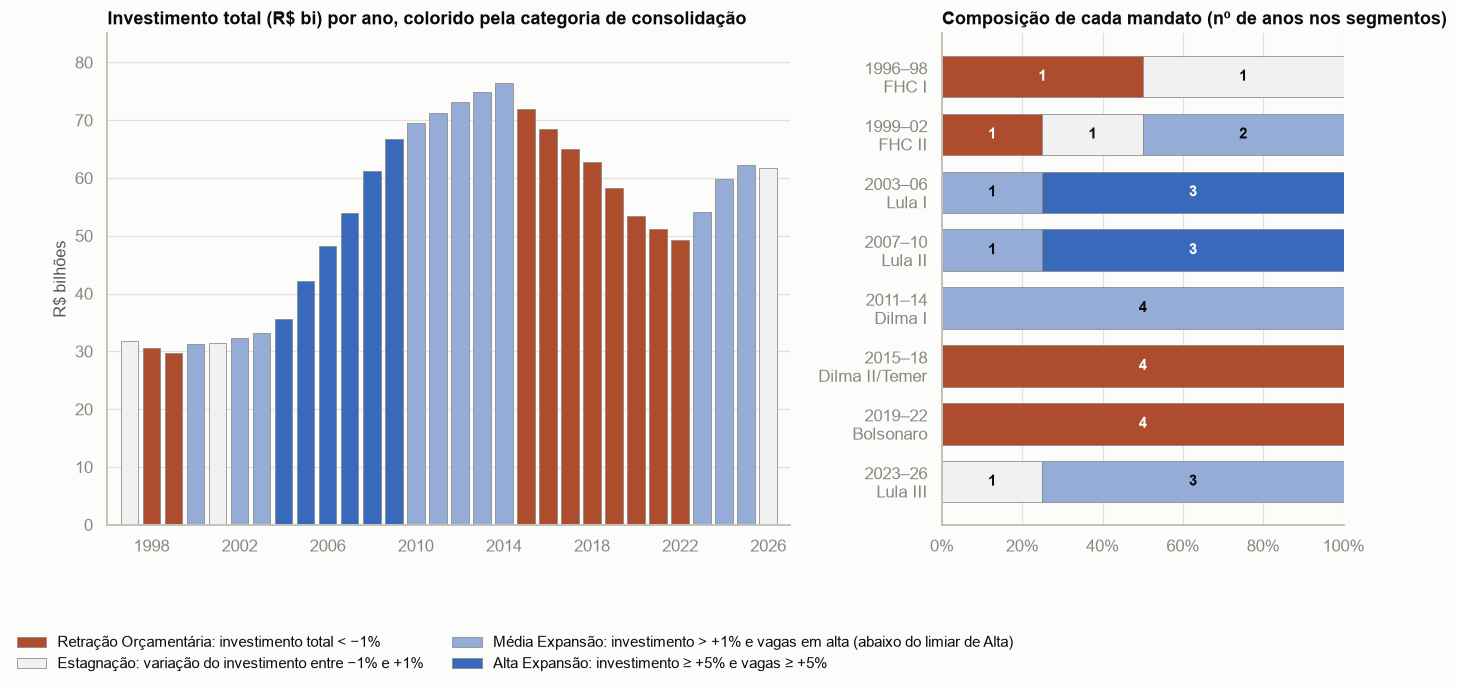

In [24]:
def cor_texto(cor):
    # texto branco sobre fundos escuros e tinta principal sobre fundos claros
    r_, g_, b_ = mpl.colors.to_rgb(cor)
    return "#ffffff" if (0.2126 * r_ + 0.7152 * g_ + 0.0722 * b_) < 0.55 else TINTA


d_cat = df.dropna(subset=["categoria"])
contagem = (pd.crosstab(d_cat["periodo"], d_cat["categoria"])
              .reindex(index=ORDEM_PERIODOS, columns=ORDEM_CAT, fill_value=0))
participacao = contagem.div(contagem.sum(axis=1), axis=0)

fig, (axl, axr) = plt.subplots(1, 2, figsize=(14.5, 5.8), gridspec_kw={"width_ratios": [1.7, 1], "wspace": 0.28})

# --- esquerda: investimento total por ano, colorido pela categoria ---
axl.bar(d_cat["ano"], d_cat["inv_total"], color=[PAL[c] for c in d_cat["categoria"]],
        edgecolor=MUDO, linewidth=0.5, width=0.8)
axl.set_title("Investimento total (R$ bi) por ano, colorido pela categoria de consolidação")
axl.set_ylabel("R$ bilhões")
axl.set_xlim(1996, 2027)
axl.set_xticks(range(1998, 2027, 4))
axl.yaxis.set_major_formatter(fmt_eixo(0))
axl.set_ylim(0, 85)

# --- direita: composição de cada mandato ---
esq = np.zeros(len(participacao))
for cat in ORDEM_CAT:
    axr.barh(range(len(participacao)), participacao[cat], left=esq, color=PAL[cat],
             edgecolor=MUDO, linewidth=0.5, height=0.72)
    for i, (frac, n) in enumerate(zip(participacao[cat], contagem[cat])):
        if n > 0:
            axr.text(esq[i] + frac / 2, i, str(n), ha="center", va="center",
                     color=cor_texto(PAL[cat]), fontsize=10, fontweight="bold")
    esq += participacao[cat].to_numpy()
axr.set_yticks(range(len(participacao)))
axr.set_yticklabels([f"{p}\n{GOVERNO[p]}" for p in participacao.index])
axr.invert_yaxis()
axr.set_xlim(0, 1)
axr.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 100:.0f}%"))
axr.set_title("Composição de cada mandato (nº de anos nos segmentos)")
axr.grid(axis="y", visible=False)
axr.grid(axis="x", visible=True)

legenda = [Patch(facecolor=PAL["Retração Orçamentária"], edgecolor=MUDO, linewidth=0.5,
                 label="Retração Orçamentária: investimento total < −1%"),
           Patch(facecolor=PAL["Estagnação"], edgecolor=MUDO, linewidth=0.5,
                 label="Estagnação: variação do investimento entre −1% e +1%"),
           Patch(facecolor=PAL["Média Expansão"], edgecolor=MUDO, linewidth=0.5,
                 label="Média Expansão: investimento > +1% e vagas em alta (abaixo do limiar de Alta)"),
           Patch(facecolor=PAL["Alta Expansão"], edgecolor=MUDO, linewidth=0.5,
                 label="Alta Expansão: investimento ≥ +5% e vagas ≥ +5%")]
fig.legend(handles=legenda, loc="lower left", ncol=2, bbox_to_anchor=(0.06, -0.14), fontsize=9.5)
salvar(fig, "07_categorias_consolidacao")
plt.show()

### Relatório visual: Figura 7

números: 6 anos de Alta Expansão (2004-2009), 11 de Média, 3 de Estagnação (1997, 2001, 2026), 10 de Retração (1998, 1999 e 2015-2022)
2015-18 e 2019-22 ficam 100% em retração; mudando os limites, no máximo 5 anos trocam de categoria
design: paleta divergente (categorias em ordem e com ponto neutro), barras por ano + composição por mandato, contorno fino, legenda com a regra de cada categoria

## 7. Relatório visual consolidado

| Fig. | Pergunta | Gráfico escolhido | Paleta / destaque | Por que (resumo) |
|---|---|---|---|---|
| 1 | Como evoluíram investimento e vagas? | 2 painéis de linha, x compartilhado, y independente | azul e laranja (categórica, ordem fixa) | unidades e escalas incompatíveis; eixo duplo "inventa" cruzamentos |
| 2 | Por que não eixo único/duplo? | evidência das alternativas descartadas | — | mostra o achatamento (a) e a arbitrariedade de escala (b) |
| 3 | Como mudou a carga por docente e por TAE? | 1 painel, 2 linhas, mesmo eixo y | azul e laranja + rótulos diretos | mesma unidade e magnitude → comparar nível, inclinação e cruzamento |
| 4 | Heatmap de correlação serve? | heatmap (descartado) | divergente centrada em 0 | correlação espúria e dependente de recorte |
| 5 | A assistência acompanhou as vagas? | bubble chart com trajetória e linha de proporção | sequencial de um matiz (ano) | revela a inversão pós-2014 e a lacuna de R$ 0,37 bi em 2026 |
| 6 | Quais são os anos críticos? | linha + marcadores destacados + barras de novas vagas | forma e cor (vermelho) + setas | anos não contíguos inviabilizam sombreamento; condição 2 visível |
| 7 | Em que fase institucional estava cada ano? | barras coloridas + composição 100% por mandato | divergente (laranja → cinza → azul) | categorias ordenadas com ponto neutro |

### Conclusões

1. Descolamento a partir de 2014: o investimento total caiu 35,6% até 2022 e as vagas de estudantes continuaram crescendo; em 2026, o orçamento ainda está 19,2% abaixo do pico e as vagas, 20,2% acima.
2. Quem absorveu a diferença: a carga por TAE subiu de 15,0 (2014) para 19,2 (2026), enquanto a carga por docente ficou estável (13,5 para 14,1). A assistência por vaga caiu 23,1% em relação a 2014.
3. Sequência de anos críticos: 8 anos (2015–2020, 2022 e 2026) combinam corte/estagnação da assistência com expansão de vagas.
4. Recuperação incompleta: 2023–2025 trazem recuperação do orçamento, mas sem retomada do ritmo de expansão de vagas (≤ 1,6% ao ano), e 2026 já volta à estagnação.

### Limitações

- Origem e unidade: o CSV não informa a fonte nem se os valores monetários são correntes ou constantes; foram usados como fornecidos. Se forem correntes, as comparações de longo prazo (1996 × 2026) deveriam ser deflacionadas (por exemplo, pelo IPCA).
- 2026 é o ano corrente; se o valor for estimativa ou dotação, as conclusões sobre o último ano são provisórias.
- Vagas são um estoque; as "novas vagas" são a diferença anual do estoque, não ofertas de vestibular.
- Mandatos são recortes de calendário e não atribuem causalidade a governos; e correlação não é causalidade (Figura 4).
- Valores iniciais de assistência (R$ 0,02–0,04 bi, resolução de 0,01) tornam variações percentuais instáveis; por isso os anos 1997, 1999 e 2001 foram tratados como inconclusivos.